In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn = pd.read_csv("processed/sn.csv", dtype={"CID": "string"})
cov = np.load("processed/sn_covariance.npz")["covariance"]

z = sn["zHD"].values
z_hel = sn["zHEL"].values
m = sn["m_b_corr"].values

assert cov.shape == (len(sn), len(sn))

In [4]:
omega_m = np.linspace(0.05, 0.60, 551)
z_grid = np.linspace(0, max(z), 4001)
dz = z_grid[1] - z_grid[0]

shape = np.zeros((len(sn), len(omega_m)))

for j, om in enumerate(omega_m):
    inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

    distance = (1 + z_hel) * np.interp(z, z_grid, integral)
    shape[:, j] = 5 * np.log10(distance)

zHD : 적색편이, m_b_corr : 겉보기등급

In [5]:
delta = m.reshape(-1, 1) - shape

L = np.linalg.cholesky(cov)
white = np.linalg.solve(
    L,
    np.column_stack((np.ones(len(sn)), delta)),
)

u = white[:, 0]
v = white[:, 1:]

offset = (u @ v) / (u @ u)
residual_white = v - u.reshape(-1, 1) * offset
chi2 = np.sum(residual_white**2, axis=0)

best = np.argmin(chi2)
dchi2 = chi2 - chi2[best]

In [6]:
assert 0 < best < len(omega_m) - 1
assert dchi2[0] > 1 and dchi2[-1] > 1

lower = np.interp(
    1, dchi2[:best + 1][::-1], omega_m[:best + 1][::-1]
)
upper = np.interp(
    1, dchi2[best:], omega_m[best:]
)

summary = pd.DataFrame({
    "Omega_m": [omega_m[best]],
    "error_minus": [omega_m[best] - lower],
    "error_plus": [upper - omega_m[best]],
    "lower_68": [lower],
    "upper_68": [upper],
    "offset": [offset[best]],
    "chi2": [chi2[best]],
    "dof": [len(sn) - 2],
    "reduced_chi2": [chi2[best] / (len(sn) - 2)],
})

profile = pd.DataFrame({
    "Omega_m": omega_m,
    "offset": offset,
    "chi2": chi2,
    "delta_chi2": dchi2,
})

summary.to_csv("results/sn_summary.csv", index=False)
profile.to_csv("results/sn_profile.csv", index=False)

summary

,Omega_m,error_minus,error_plus,lower_68,upper_68,offset,chi2,dof,reduced_chi2
0,0.332,0.018389,0.018004,0.313611,0.350004,23.807368,1402.92018,1588,0.883451


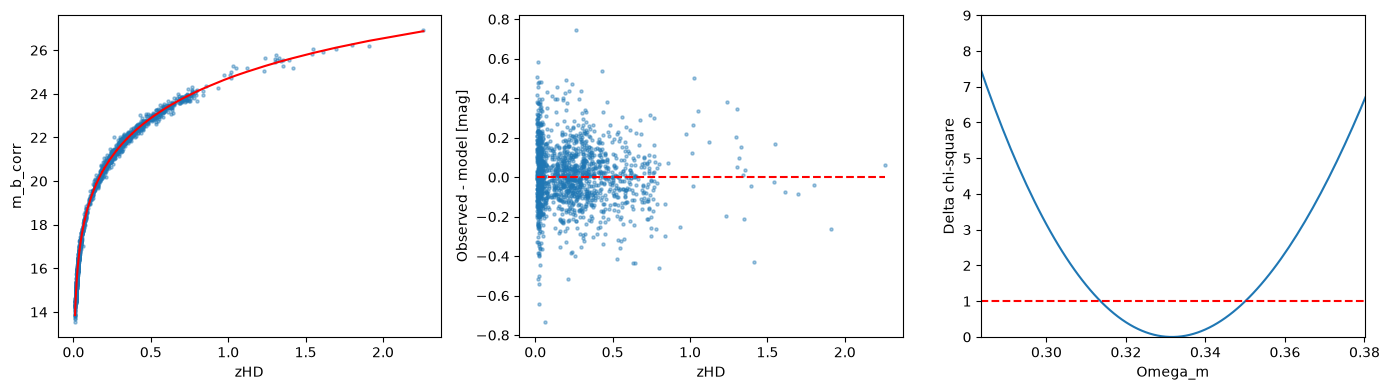

In [7]:
prediction = shape[:, best] + offset[best]
residual = m - prediction
order = np.argsort(z)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.scatter(z, m, s=5, alpha=0.4)
plt.plot(z[order], prediction[order], color="red")
plt.xlabel("zHD")
plt.ylabel("m_b_corr")

plt.subplot(1, 3, 2)
plt.scatter(z, residual, s=5, alpha=0.4)
plt.plot([min(z), max(z)], [0, 0], "r--")
plt.xlabel("zHD")
plt.ylabel("Observed - model [mag]")

plt.subplot(1, 3, 3)
plt.plot(omega_m, dchi2)
plt.plot([omega_m[0], omega_m[-1]], [1, 1], "r--")
plt.axis([lower - 0.03, upper + 0.03, 0, 9])
plt.xlabel("Omega_m")
plt.ylabel("Delta chi-square")

plt.tight_layout()
plt.show()

pd.DataFrame({
    "CID": sn["CID"],
    "zHD": z,
    "observed": m,
    "model": prediction,
    "residual": residual,
}).to_csv("results/sn_residuals.csv", index=False)